# 08 · Évaluation finale sur le test


## Ce qui est fixé avant l'ouverture

| Élément | Valeur | Fixé dans |
|---|---|---|
| Champion | Règle « Pannes sur 7 jours » (aucun apprentissage) | Notebook 07, `config.yaml` |
| Challenger | Boosting prudent avec le site, réglages du notebook 07 | Notebook 07, `config.yaml` |
| Données d'apprentissage du challenger | **Entraînement + validation** (janvier 2020 à avril 2021) | Ici, avant ouverture |
| Règle de décision | +3 points de précision@10, intervalle de confiance excluant 0, aucun mois perdant | Notebook 06 |

**Pourquoi réentraîner le challenger sur l'entraînement et la validation ?** Les réglages ont été choisis ; la validation a fini son rôle. La réutiliser pour apprendre donne au modèle quatre mois plus récents, donc plus proches du test. C'est la pratique standard, et c'est ce modèle-là qui serait mis en service. On ne change **rien d'autre**.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.calibration import calibration_curve

from evrel.data.load import get_data_dir, load_config
from evrel.models.baselines import baseline_scores
from evrel.models.compare import decision, monthly_precision
from evrel.models.evaluate import evaluate_ranking, top_k_rows
from evrel.models.train import BASELINE, log_baseline, run_experiment, setup_mlflow
from evrel.viz import INK_2, NEUTRAL, PALETTE, set_style

set_style()
setup_mlflow()
cfg = load_config()
spec = cfg["models"]["challenger"]
feats = pd.read_parquet(get_data_dir() / "processed" / "features.parquet")

fit_data = feats[feats["split"].isin(["train", "valid"])].copy()
test = feats[feats["split"] == "test"].copy()
test[BASELINE] = baseline_scores(test)[BASELINE]
print(f"Apprentissage du challenger : {len(fit_data):,} lignes ({fit_data['target_date'].min():%d/%m/%Y} au {fit_data['target_date'].max():%d/%m/%Y})")
print(f"Test : {len(test):,} lignes, {test['target_date'].nunique()} soirs, {test['y'].mean():.1%} d'épisodes")

Apprentissage du challenger : 36,620 lignes (08/01/2020 au 30/04/2021)
Test : 10,579 lignes, 123 soirs, 7.7% d'épisodes


## 1. Ouverture du test

In [2]:
tags = {"stage": "test_final"}
champion = log_baseline(test, run_name="Test final · champion (règle)", tags=tags)
challenger, scores = run_experiment(fit_data, test, spec["kind"], spec["use_site"],
                                    run_name="Test final · challenger (boosting)", tags=tags, **spec["params"])
test["challenger"] = scores

keys = ["précision@10", "rappel@10", "précision@5", "rappel@5", "PR-AUC", "AUC"]
results = pd.DataFrame({"Champion (règle)": {k: champion[k] for k in keys},
                        "Challenger (boosting)": {k: challenger[k] for k in keys}})
results["écart"] = results["Challenger (boosting)"] - results["Champion (règle)"]
results.round(3)

2026/10/11 23:45:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\orose\OneDrive\Documents\omr-portfolio\projects\ml-mlops\ev-charging-reliability\.venv\lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as double

,Champion (règle),Challenger (boosting),écart
précision@10,0.172,0.235,0.063
rappel@10,0.259,0.353,0.094
précision@5,0.213,0.294,0.081
rappel@5,0.160,0.221,0.061
PR-AUC,0.155,0.280,0.125
AUC,0.707,0.770,0.062


## 2. La règle de décision appliquée au test

In [3]:
dec = decision(test, "challenger", BASELINE, min_gain=cfg["evaluation"]["decision"]["min_gain"],
               n_boot=cfg["evaluation"]["decision"]["n_boot"], confidence=cfg["evaluation"]["decision"]["confidence"])
print(f"Gain de précision@10 : {dec['gain']*100:+.2f} points, IC 95 % [{dec['ic_bas']*100:+.2f} ; {dec['ic_haut']*100:+.2f}]")
pd.Series({
    "1. Gain d'au moins 3 points": dec["c1_gain_suffisant"],
    "2. Gain significatif": dec["c2_gain_significatif"],
    "3. Aucun mois perdant": dec["c3_aucun_mois_perdant"],
    "Challenger promu champion": dec["retenu"],
}).to_frame("respectée")

Gain de précision@10 : +6.26 points, IC 95 % [+4.14 ; +8.37]


,respectée
1. Gain d'au moins 3 points,True
2. Gain significatif,True
3. Aucun mois perdant,True
Challenger promu champion,True


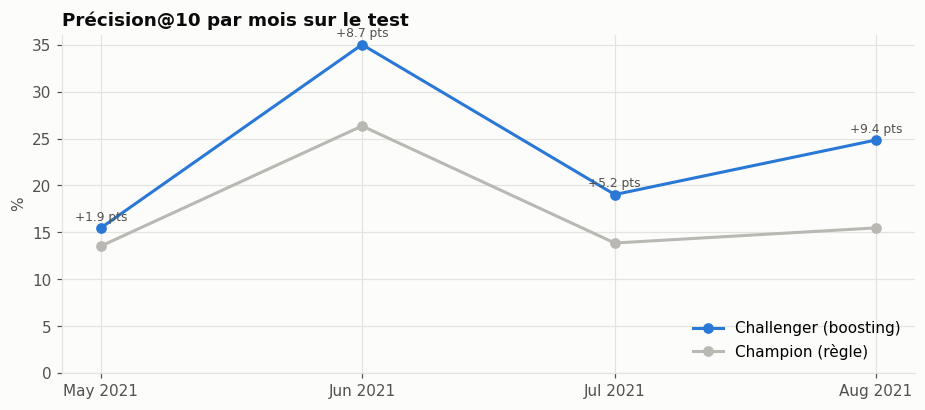

In [4]:
months = monthly_precision(test, ["challenger", BASELINE]) * 100
fig, ax = plt.subplots()
ax.plot(months.index.to_timestamp(), months["challenger"], marker="o", color=PALETTE[0], label="Challenger (boosting)")
ax.plot(months.index.to_timestamp(), months[BASELINE], marker="o", color=NEUTRAL, label="Champion (règle)")
for x, (c, b) in zip(months.index.to_timestamp(), months.values):
    ax.text(x, max(c, b) + 0.8, f"{c - b:+.1f} pts", ha="center", fontsize=8, color=INK_2)
ax.set_title("Précision@10 par mois sur le test")
ax.set_ylabel("%")
ax.set_ylim(bottom=0)
ax.legend(loc="lower right")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

**Constat** : le challenger atteint 23,5 % de précision@10 contre 17,2 % pour la règle, soit un gain de +6,26 points, avec un intervalle de confiance à 95 % de [+4,14 ; +8,37]. Il est meilleur chaque mois : +1,9 point en mai, +8,7 en juin, +5,2 en juillet, +9,4 en août. Les trois conditions de la règle de décision sont remplies.

## 3. Calibration sur le test

La fréquence des épisodes est plus élevée sur le test (environ 7,7 %) qu'à l'apprentissage. On vérifie si les probabilités restent fiables.

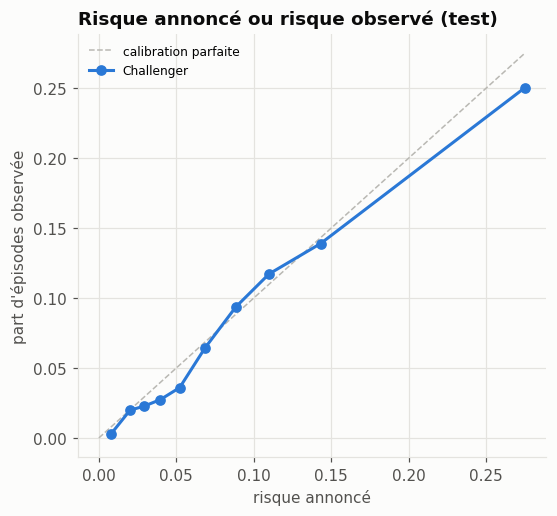

Risque moyen annoncé : 8.3%   Taux réel : 7.7%   Brier : 0.0631


In [5]:
prob_true, prob_pred = calibration_curve(test["y"], test["challenger"], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, prob_pred.max()], [0, prob_pred.max()], color=NEUTRAL, ls="--", lw=1, label="calibration parfaite")
ax.plot(prob_pred, prob_true, marker="o", color=PALETTE[0], label="Challenger")
ax.set_title("Risque annoncé ou risque observé (test)")
ax.set_xlabel("risque annoncé")
ax.set_ylabel("part d'épisodes observée")
ax.legend(fontsize=8)
plt.show()
print(f"Risque moyen annoncé : {test['challenger'].mean():.1%}   Taux réel : {test['y'].mean():.1%}   Brier : {challenger['brier']:.4f}")

**Constat** : le challenger annonce un risque moyen de 8,3 % pour 7,7 % d'épisodes réels. La courbe reste proche de la diagonale, avec une légère surestimation des risques élevés.

## 4. Diversité des listes sur le test

In [6]:
def diversity(col):
    top = top_k_rows(test, col, 10)
    freq = top["post_id"].value_counts()
    return {"bornes différentes": freq.size,
            "part des 10 plus fréquentes %": round(freq.head(10).sum() / freq.sum() * 100, 1),
            "bornes pas déjà en épisode %": round((1 - top["episode_d0"].mean()) * 100, 1)}

pd.DataFrame({"Challenger (boosting)": diversity("challenger"), "Champion (règle)": diversity(BASELINE)}).T

,bornes différentes,part des 10 plus fréquentes %,bornes pas déjà en épisode %
Challenger (boosting),61.0,49.1,58.9
Champion (règle),43.0,59.6,77.6


**Constat** : la liste du challenger est plus variée que celle de la règle : 61 bornes différentes contre 43, et 49,1 % des places occupées par les 10 bornes les plus fréquentes contre 59,6 %. En revanche, 41,1 % de sa liste est déjà en épisode le jour même, contre 22,4 % pour la règle : le modèle s'appuie davantage sur la persistance.

## 5. Validation et test côte à côte

Un modèle fiable donne des résultats du même ordre sur la validation et sur le test. Un écart important signalerait que la validation avait été « trop bien » exploitée, ou que la période a changé.

In [7]:
side = pd.DataFrame({
    "validation : champion": [0.1733, None], "validation : challenger": [0.2025, None],
}, index=["précision@10", "gain (pts)"])
side.loc["gain (pts)", "validation : challenger"] = (0.2025 - 0.1733) * 100
side["test : champion"] = [champion["précision@10"], None]
side["test : challenger"] = [challenger["précision@10"], dec["gain"] * 100]
side.round(3)

,validation : champion,validation : challenger,test : champion,test : challenger
précision@10,0.173,0.202,0.172,0.235
gain (pts),NaN,2.920,NaN,6.260


**Constat** : la règle est stable entre validation et test (17,3 % puis 17,2 %). Le gain du challenger passe de +2,9 points en validation à +6,3 points au test. Deux raisons : il a été réentraîné sur quatre mois plus récents, et le test contient plus d'épisodes (7,7 % contre 6,2 %). Le test n'ayant jamais été regardé avant cette exécution, ce gain n'est pas le fruit d'un ajustement.

## 6. Décision finale

Les trois conditions de la règle de décision sont remplies sur le test. **Le boosting prudent avec le site devient champion** ; la règle « Pannes sur 7 jours » devient la solution de repli. La période de septembre à décembre 2021, jamais regardée, est réservée à la production simulée et au monitoring.

## Ce qu'on retient

- **Le modèle bat nettement le bon sens sur des données jamais vues** : 23,5 % de déplacements utiles contre 17,2 %, soit environ 77 interventions utiles de plus sur 4 mois à effectif égal.
- **Le gain est solide** : intervalle de confiance de +4,1 à +8,4 points, et meilleur chaque mois.
- **La règle fixée à l'avance a été respectée jusqu'au bout** : en validation, le modèle a manqué le seuil d'une inspection sur 1 200 ; il a été mis en challenger plutôt que de changer le seuil, et c'est le test qui a tranché.
- **Probabilités fiables et liste plus variée** ; point de vigilance : 41 % de la liste est déjà en épisode le jour même.